In [1]:
# ============================================================
# 08 · Cell 1 — Setup and data load
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from commodity_factors.analytics import PerformanceReport, newey_west_tstat
from commodity_factors.config import PATHS, UNIVERSE

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

SIGNALS = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure", "tsmom_12"]


def load(name: str) -> pd.DataFrame:
    return pd.read_parquet(PATHS.processed / f"{name}.parquet")


factor_returns = load("factor_returns_headline")
LAST_MONTH = factor_returns.index.max()

signal_panel = load("signals")
signals = {name: signal_panel[name].loc[:LAST_MONTH] for name in SIGNALS}
monthly_returns = load("returns_monthly").loc[:LAST_MONTH]
daily_returns = load("returns_daily")
prices = load("prices_clean")
combos = load("combination_returns")
benchmarks = load("benchmarks_monthly").loc[:LAST_MONTH]
macro = pd.read_parquet(PATHS.raw / "fred_macro.parquet")
indices = pd.read_parquet(PATHS.raw / "yahoo_indices.parquet")
sectors = pd.Series(UNIVERSE.sector_map)

print(f"Last complete month : {LAST_MONTH:%Y-%m}")
print(f"Monthly returns     : {monthly_returns.shape[0]} months x {monthly_returns.shape[1]} contracts")
print(f"Signals             : {', '.join(SIGNALS)}\n")

all_six = sum(signals[name].notna().astype(int) for name in SIGNALS).eq(len(SIGNALS))
coverage = all_six.sum(axis=1)
print("Contracts with all six signals available (yearly average)")
print(coverage.groupby(coverage.index.year).mean().loc[2002:].round(1).to_frame("n").T.to_string())

Last complete month : 2026-09
Monthly returns     : 321 months x 26 contracts
Signals             : mom_12_1, carry, value, skewness, hedging_pressure, tsmom_12

Contracts with all six signals available (yearly average)
date  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
n      0.0   0.0   0.0   6.2  18.6  21.0  21.0  21.8  22.2  23.0  23.2  24.0  24.0  25.5  26.0  26.0  26.0  26.0  26.0  26.0  25.2  25.6  25.2  25.0  25.0


In [4]:
%%writefile src/commodity_factors/ml_commodity.py
"""Commodity-level features for learning which factor signals work in which regime."""

from __future__ import annotations

import numpy as np
import pandas as pd

RANKED_SIGNALS = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure"]


def centred_rank(signal: pd.DataFrame) -> pd.DataFrame:
    """Cross-sectional rank scaled to [-1, 1] each month (missing stays missing)."""
    n = signal.notna().sum(axis=1)
    return signal.rank(axis=1).sub((n + 1) / 2, axis=0).div((n - 1) / 2, axis=0)


def month_end_by_column(frame: pd.DataFrame) -> pd.DataFrame:
    """Last available value per column in each month (gaps in one column do not affect others)."""
    return frame.resample("ME").last()


class CommodityFeatureBuilder:
    """Panel of (month-end, commodity) rows for predicting next-month relative returns.

    signal_*  : the six factor signals (five cross-sectional ranks in [-1, 1], plus the
                TSMOM sign); missing signals are set to 0 (neutral).
    own regime: the commodity's own volatility state, short-term trend, distance from its
                12-month high, curve state and how extreme hedger positioning is.
    market    : the shared market features from notebook 07.
    target    : next-month return per unit of own volatility, minus the cross-sectional
                mean (relative, risk-adjusted). target_raw keeps the plain return.
    All features use information available at the close of month t.
    """

    SIGNAL_FEATURES = [f"signal_{s}" for s in RANKED_SIGNALS] + ["signal_tsmom_12"]
    REGIME_FEATURES = ["own_vol_12m", "own_vol_ratio", "own_trend_3m", "own_from_high",
                       "own_backwardated", "own_hp_extreme"]

    def __init__(self, signals, monthly_returns, daily_returns, return_index, sectors,
                 market_features: pd.DataFrame, min_signals: int = 4) -> None:
        self._signals = signals
        self._monthly = monthly_returns
        self._daily = daily_returns
        self._index = return_index
        self._sectors = sectors
        self._market = market_features
        self._min_signals = min_signals

    def _signal_features(self) -> dict[str, pd.DataFrame]:
        features = {f"signal_{s}": centred_rank(self._signals[s]) for s in RANKED_SIGNALS}
        features["signal_tsmom_12"] = np.sign(self._signals["tsmom_12"])
        return features

    def _regime_features(self) -> dict[str, pd.DataFrame]:
        daily = self._daily

        def vol(days: int) -> pd.DataFrame:
            rolling = daily.rolling(days, min_periods=int(days * 0.8)).std()
            return month_end_by_column(rolling) * np.sqrt(252)

        index_m = month_end_by_column(self._index)
        hp = self._signals["hedging_pressure"]
        hp_z = (hp - hp.rolling(36, min_periods=24).mean()) / hp.rolling(36, min_periods=24).std()
        carry = self._signals["carry"]
        return {
            "own_vol_12m": vol(252),
            "own_vol_ratio": vol(63) / vol(756),
            "own_trend_3m": index_m / index_m.shift(3) - 1,
            "own_from_high": index_m / index_m.rolling(12, min_periods=12).max() - 1,
            "own_backwardated": (carry > 0).astype(float).where(carry.notna()),
            "own_hp_extreme": hp_z,
        }

    def panel(self) -> pd.DataFrame:
        dates, symbols = self._monthly.index, self._monthly.columns
        signal_features = self._signal_features()
        n_signals = sum(f.reindex(index=dates, columns=symbols).notna().astype(int)
                        for f in signal_features.values())

        stacked = {
            name: frame.reindex(index=dates, columns=symbols).stack(future_stack=True)
            for name, frame in {**signal_features, **self._regime_features()}.items()
        }
        panel = pd.DataFrame(stacked)
        panel.index.names = ["date", "symbol"]
        panel["n_signals"] = n_signals.stack(future_stack=True)

        next_return = self._monthly.shift(-1).stack(future_stack=True)
        next_return.index.names = ["date", "symbol"]
        panel["target_raw"] = next_return
        scaled = panel["target_raw"] / (panel["own_vol_12m"] / np.sqrt(12))
        panel["target"] = scaled - scaled.groupby(level="date").transform("mean")

        market = self._market.reindex(panel.index.get_level_values("date"))
        market.index = panel.index
        panel = pd.concat([panel, market], axis=1)
        panel["sector"] = panel.index.get_level_values("symbol").map(self._sectors)

        has_return = self._monthly.stack(future_stack=True).reindex(panel.index).notna()
        panel = panel.loc[has_return & panel["n_signals"].ge(self._min_signals)].copy()
        panel[self.SIGNAL_FEATURES] = panel[self.SIGNAL_FEATURES].fillna(0.0)
        return panel

Overwriting src/commodity_factors/ml_commodity.py


In [5]:
# ============================================================
# 08 · Cell 3 — Build the panel and explore conditional signal strength
# ============================================================
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
from commodity_factors.ml import FactorFeatureBuilder
from commodity_factors.ml_commodity import CommodityFeatureBuilder, centred_rank

return_index = load("return_index")
market_features = FactorFeatureBuilder(
    factor_returns=factor_returns, market_returns=benchmarks["EW_all"],
    cpi=macro["cpi"], dxy=indices["dxy"], vix=macro["vix"],
).market_features()

builder = CommodityFeatureBuilder(signals, monthly_returns, daily_returns, return_index,
                                  sectors, market_features)
panel = builder.panel()
SIGNAL_COLS = CommodityFeatureBuilder.SIGNAL_FEATURES
REGIME_COLS = CommodityFeatureBuilder.REGIME_FEATURES
MARKET_COLS = FactorFeatureBuilder.MARKET_FEATURES
complete = panel.dropna(subset=REGIME_COLS + MARKET_COLS + ["target"])

# 1. Coverage
per_month = complete.groupby(level="date").size()
print(f"Panel: {len(panel):,} rows | complete: {len(complete):,} | "
      f"{per_month.index.min():%Y-%m} -> {per_month.index.max():%Y-%m} | "
      f"commodities per month: median {per_month.median():.0f}, min {per_month.min()}\n")

# 2. Timing check (WTI, Dec 2024)
check = (pd.Timestamp("2024-12-31"), "CL")
expected_rank = centred_rank(signals["mom_12_1"]).at[check]
print("Timing check: CL at 2024-12-31")
print(f"  momentum rank  expected {expected_rank:.4f} | panel {panel.at[check, 'signal_mom_12_1']:.4f}")
print(f"  target_raw     expected {monthly_returns.at[pd.Timestamp('2025-01-31'), 'CL']:.4f} | "
      f"panel {panel.at[check, 'target_raw']:.4f}  (= Jan 2025 return)\n")


def monthly_ic(rows: pd.DataFrame, feature: str, min_names: int = 6) -> tuple[float, float]:
    """Mean monthly rank IC of a feature vs the target, and its t-statistic."""
    ic = rows.groupby(level="date").apply(
        lambda g: g[feature].rank().corr(g["target"].rank()) if len(g) >= min_names else np.nan
    ).dropna()
    return ic.mean(), ic.mean() / ic.std() * np.sqrt(len(ic))


# 3. Baseline IC
baseline = pd.DataFrame({f: dict(zip(["ic", "t"], monthly_ic(complete, f))) for f in SIGNAL_COLS}).T
print("Baseline monthly IC of each signal (all commodities)")
print(baseline.round(3).to_string(), "\n")

# 4. Conditional ICs by the commodity's own regime
turbulent = complete["own_vol_ratio"] > complete.groupby(level="date")["own_vol_ratio"].transform("median")
groups = {
    "turbulent": turbulent, "calm": ~turbulent,
    "backwardated": complete["own_backwardated"] == 1, "contango": complete["own_backwardated"] == 0,
    "hp_extreme": complete["own_hp_extreme"].abs() > 1, "hp_normal": complete["own_hp_extreme"].abs() <= 1,
}
conditional_ic, conditional_t = {}, {}
for label, mask in groups.items():
    stats = {f: monthly_ic(complete.loc[mask], f) for f in SIGNAL_COLS}
    conditional_ic[label] = {f: s[0] for f, s in stats.items()}
    conditional_t[label] = {f: s[1] for f, s in stats.items()}
print("Conditional monthly IC by the commodity's own regime")
print(pd.DataFrame(conditional_ic).round(3).to_string(), "\n")
print("Conditional IC t-statistics")
print(pd.DataFrame(conditional_t).round(2).to_string(), "\n")

# 5. Sector: pooled rank correlation (some sectors are too small for monthly ICs)
sector_corr = pd.DataFrame(
    {sector: {f: rows[f].rank().corr(rows["target"].rank()) for f in SIGNAL_COLS}
     for sector, rows in complete.groupby("sector")}
)
print("Pooled rank correlation with the target, by sector")
print(sector_corr.round(3).to_string())

Panel: 7,451 rows | complete: 6,751 | 2002-06 -> 2026-08 | commodities per month: median 25, min 4

Timing check: CL at 2024-12-31
  momentum rank  expected 0.2000 | panel 0.2000
  target_raw     expected 0.0173 | panel 0.0173  (= Jan 2025 return)

Baseline monthly IC of each signal (all commodities)
                            ic      t
signal_mom_12_1          0.025  1.666
signal_carry             0.034  2.352
signal_value             0.038  2.322
signal_skewness          0.051  3.621
signal_hedging_pressure  0.051  3.357
signal_tsmom_12          0.015  1.040 

Conditional monthly IC by the commodity's own regime
                         turbulent   calm  backwardated  contango  hp_extreme  hp_normal
signal_mom_12_1              0.015  0.039        -0.009     0.045       0.004      0.040
signal_carry                 0.038  0.014         0.018     0.038       0.033      0.034
signal_value                 0.057  0.026         0.046     0.028       0.073     -0.016
signal_skewness      

In [6]:
%%writefile -a src/commodity_factors/ml_commodity.py


class CommodityWalkForward:
    """Expanding-window, yearly-retrained predictions for a (date, symbol) panel.

    For each test year Y the model is fitted on rows dated before 31 Dec of Y-1 and predicts
    rows dated 31 Dec Y-1 to 30 Nov Y (returns of January to December Y).

    Design matrix: signals, own-regime and market features, sector dummies and, optionally,
    every signal interacted with every regime, market and sector column. The interactions
    let a linear model learn that a signal works better in some regimes or sectors.
    """

    def __init__(self, model_factory, signal_cols, regime_cols, market_cols,
                 target: str = "target", first_test_year: int = 2010,
                 interactions: bool = True) -> None:
        self._factory = model_factory
        self._signals, self._regimes, self._market = signal_cols, regime_cols, market_cols
        self._target = target
        self._first_test_year = first_test_year
        self._interactions = interactions

    def design_matrix(self, panel: pd.DataFrame) -> pd.DataFrame:
        sector_dummies = pd.get_dummies(panel["sector"], prefix="sector", dtype=float)
        base = pd.concat([panel[self._signals + self._regimes + self._market], sector_dummies], axis=1)
        if not self._interactions:
            return base
        conditioners = pd.concat([panel[self._regimes + self._market], sector_dummies], axis=1)
        crosses = [
            conditioners.mul(panel[signal], axis=0).add_prefix(f"{signal}_x_")
            for signal in self._signals
        ]
        return pd.concat([base, *crosses], axis=1)

    def predict(self, panel: pd.DataFrame) -> pd.Series:
        rows = panel.dropna(subset=self._regimes + self._market)
        X = self.design_matrix(rows)
        y = rows[self._target]
        dates = rows.index.get_level_values("date")
        last_year = dates.max().year + (1 if dates.max().month == 12 else 0)

        predictions = []
        for year in range(self._first_test_year, last_year + 1):
            cutoff = pd.Timestamp(year=year - 1, month=12, day=31)
            train = (dates < cutoff) & y.notna().to_numpy()
            test = (dates >= cutoff) & (dates < pd.Timestamp(year=year, month=12, day=31))
            if not test.any() or train.sum() < 200:
                continue
            model = self._factory()
            model.fit(X[train], y[train])
            predictions.append(pd.Series(model.predict(X[test]), index=X.index[test]))
        return pd.concat(predictions).rename("prediction").sort_index()

Appending to src/commodity_factors/ml_commodity.py


In [7]:
# ============================================================
# 08 · Cell 5 — Models and walk-forward out-of-sample predictions
# ============================================================
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from commodity_factors.ml_commodity import CommodityWalkForward

FIRST_TEST_YEAR = 2010
common = dict(signal_cols=SIGNAL_COLS, regime_cols=REGIME_COLS, market_cols=MARKET_COLS,
              target="target", first_test_year=FIRST_TEST_YEAR)

engines = {
    "ridge": CommodityWalkForward(
        lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 6, 25))),
        interactions=True, **common,
    ),
    "gbm": CommodityWalkForward(
        lambda: GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.02,
                                          subsample=0.7, min_samples_leaf=100, random_state=42),
        interactions=False, **common,
    ),
}
commodity_predictions = {name: engine.predict(panel) for name, engine in engines.items()}

# Benchmark: simple composite (average of the six signals), no training
oos_index = commodity_predictions["ridge"].index
commodity_predictions["composite"] = panel[SIGNAL_COLS].mean(axis=1).reindex(oos_index)
commodity_predictions = pd.DataFrame(commodity_predictions)

dates = commodity_predictions.index.get_level_values("date")
print(f"Out-of-sample: {dates.min():%Y-%m} -> {dates.max():%Y-%m} | rows: {len(commodity_predictions):,}\n")


def evaluate_commodity(prediction: pd.Series) -> dict:
    """Monthly rank IC vs relative target, and the top-minus-bottom tercile return spread."""
    data = pd.concat({"pred": prediction, "rel": panel["target"], "ret": panel["target_raw"]},
                     axis=1).dropna()
    by_month = data.groupby(level="date")
    ic = by_month.apply(lambda g: g["pred"].rank().corr(g["rel"].rank())).dropna()

    def tercile_spread(g: pd.DataFrame) -> float:
        n = max(len(g) // 3, 1)
        return g.nlargest(n, "pred")["ret"].mean() - g.nsmallest(n, "pred")["ret"].mean()

    spread = by_month.apply(tercile_spread)
    return {
        "mean_ic": ic.mean(),
        "ic_t_stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
        "ic_positive_%": ic.gt(0).mean() * 100,
        "spread_ann_%": spread.mean() * 1200,
        "spread_t_nw": newey_west_tstat(spread),
        "months": len(ic),
    }


commodity_results = pd.DataFrame(
    {name: evaluate_commodity(commodity_predictions[name]) for name in commodity_predictions.columns}
).T
print("Out-of-sample prediction quality (2010 onwards, before costs)")
print(commodity_results.round(3).to_string(), "\n")

print("Correlation between model predictions (pooled)")
print(commodity_predictions.corr().round(2).to_string())

Out-of-sample: 2009-12 -> 2026-09 | rows: 5,055

Out-of-sample prediction quality (2010 onwards, before costs)
           mean_ic  ic_t_stat  ic_positive_%  spread_ann_%  spread_t_nw  months
ridge        0.040      2.301           56.0         7.052        1.561   200.0
gbm          0.047      2.893           56.0         8.337        1.829   200.0
composite    0.059      3.317           59.5         9.382        2.605   200.0 

Correlation between model predictions (pooled)
           ridge   gbm  composite
ridge       1.00  0.58       0.47
gbm         0.58  1.00       0.28
composite   0.47  0.28       1.00


In [8]:
# ============================================================
# 08 · Cell 6 — Long-short portfolios with full costs
# ============================================================
from commodity_factors.contracts import CONTRACT_SPECS
from commodity_factors.portfolio import Backtester, QuantileLongShort

COST = 0.0005
backtester = Backtester(monthly_returns, cost_per_turnover=COST)
rolls_per_month = pd.Series({s: len(spec.month_codes) / 12 for s, spec in CONTRACT_SPECS.items()})


def net_of_all_costs(result) -> pd.Series:
    """Gross return minus 5 bps on rebalancing and estimated roll turnover."""
    held = result.weights.abs().reindex(columns=rolls_per_month.index).fillna(0.0)
    rolls = (held * rolls_per_month).sum(axis=1).reindex(monthly_returns.index).shift(1)
    total_turnover = result.turnover + rolls.reindex(result.gross.index)
    return result.gross - total_turnover * COST


# Score panels (date x commodity); post-hoc ensemble = average of composite and gbm ranks
scores = {name: commodity_predictions[name].unstack("symbol") for name in commodity_predictions.columns}
scores["ensemble_posthoc"] = (scores["composite"].rank(axis=1, pct=True)
                              + scores["gbm"].rank(axis=1, pct=True)) / 2

portfolio_results = {name: backtester.run(QuantileLongShort().weights(score), start="2009-12-31")
                     for name, score in scores.items()}
ls_net = pd.DataFrame({name: net_of_all_costs(res) for name, res in portfolio_results.items()})
ls_net["equal_risk_factor_blend"] = combos["combo_equal_risk"]
ls_net = ls_net.loc["2010-01":].dropna()

# 1. Performance
columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw", "max_dd_%", "skew"]
ls_table = PerformanceReport(ls_net).table()[columns]
ls_table["turnover_pa"] = pd.Series({n: r.turnover.mean() * 12 for n, r in portfolio_results.items()})
print("Long-short portfolios, Jan 2010 to Sep 2026 (net of rebalancing and roll costs)")
print(ls_table.to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# 2. Head-to-head comparisons (monthly return differences)
pairs = [("ridge", "composite"), ("gbm", "composite"), ("ensemble_posthoc", "composite"),
         ("composite", "equal_risk_factor_blend"), ("gbm", "equal_risk_factor_blend")]
head_to_head = {}
for a, b in pairs:
    diff = ls_net[a] - ls_net[b]
    head_to_head[f"{a} - {b}"] = {"diff_ann_%": diff.mean() * 1200, "t_stat_nw": newey_west_tstat(diff),
                                  "correlation": ls_net[a].corr(ls_net[b])}
print("Head-to-head: return difference per year and correlation")
print(pd.DataFrame(head_to_head).T.round(2).to_string(), "\n")

# 3. Subperiods
halves = {"2010-2017": ("2010", "2017"), "2018-2026": ("2018", "2026")}
print("Sharpe ratio by subperiod")
print(pd.DataFrame({label: ls_net.loc[a:b].apply(lambda r: r.mean() / r.std() * np.sqrt(12))
                    for label, (a, b) in halves.items()}).round(2).to_string())

Long-short portfolios, Jan 2010 to Sep 2026 (net of rebalancing and roll costs)
                           start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_%  skew  turnover_pa
ridge                    2010-01    200         5.12     18.89   0.27      1.19   -44.88 -0.21         8.97
gbm                      2010-01    200         7.84     17.47   0.45      1.72   -49.31  0.34        14.20
composite                2010-01    200         7.49     17.51   0.43      2.10   -36.15 -0.35         9.08
ensemble_posthoc         2010-01    200        10.30     16.69   0.62      2.68   -34.38 -0.14        12.12
equal_risk_factor_blend  2010-01    200         4.53      8.26   0.55      2.65   -13.78 -0.54          NaN 

Head-to-head: return difference per year and correlation
                                     diff_ann_%  t_stat_nw  correlation
ridge - composite                         -2.37      -0.56         0.49
gbm - composite                            0.35       0.07         0.

In [9]:
# ============================================================
# 08 · Cell 7 — Interpretability: which signals the models use, and where
# ============================================================
rows = panel.dropna(subset=REGIME_COLS + MARKET_COLS + ["target"])

# 1. Ridge: largest signal x regime / market / sector interaction coefficients
ridge_engine = engines["ridge"]
X_ridge = ridge_engine.design_matrix(rows)
ridge_model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 6, 25))).fit(X_ridge, rows["target"])
coefficients = pd.Series(ridge_model[-1].coef_, index=X_ridge.columns)
interactions = coefficients[coefficients.index.str.contains("_x_")]
print(f"Ridge (all data, alpha = {ridge_model[-1].alpha_:.0f}): 12 largest interaction coefficients")
print(interactions.reindex(interactions.abs().sort_values(ascending=False).index).head(12).round(4).to_string(), "\n")

# 2. Gradient boosting: conditional effect of moving each signal from -1 to +1
gbm_engine = engines["gbm"]
X_gbm = gbm_engine.design_matrix(rows)
gbm_model = GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.02, subsample=0.7,
                                      min_samples_leaf=100, random_state=42).fit(X_gbm, rows["target"])

turbulent = rows["own_vol_ratio"] > rows.groupby(level="date")["own_vol_ratio"].transform("median")
groups = {"turbulent": turbulent, "calm": ~turbulent,
          "backwardated": rows["own_backwardated"] == 1, "contango": rows["own_backwardated"] == 0}

effects = {}
for signal in SIGNAL_COLS:
    high, low = X_gbm.copy(), X_gbm.copy()
    high[signal], low[signal] = 1.0, -1.0
    change = pd.Series(gbm_model.predict(high) - gbm_model.predict(low), index=X_gbm.index)
    effects[signal] = {label: change[mask].mean() for label, mask in groups.items()}
effects = pd.DataFrame(effects).T
effects["turbulent_minus_calm"] = effects["turbulent"] - effects["calm"]
print("Gradient boosting: predicted effect of a signal moving from bottom (-1) to top (+1) rank")
print("(units: risk-adjusted relative return; larger = the model relies on that signal more)")
print(effects.round(3).to_string(), "\n")

importance = pd.Series(gbm_model.feature_importances_, index=X_gbm.columns).sort_values(ascending=False)
print("Gradient boosting: top 10 features by importance")
print(importance.head(10).round(3).to_string())

Ridge (all data, alpha = 10000): 12 largest interaction coefficients
signal_value_x_sector_Livestock              -0.0124
signal_hedging_pressure_x_mkt_ret_12m        -0.0113
signal_value_x_sector_Softs                   0.0103
signal_mom_12_1_x_sector_Softs                0.0097
signal_value_x_own_vol_12m                    0.0095
signal_tsmom_12_x_sector_Energy               0.0090
signal_carry_x_sector_Grains                  0.0088
signal_value_x_own_from_high                 -0.0087
signal_hedging_pressure_x_own_backwardated    0.0079
signal_skewness_x_own_vol_ratio               0.0075
signal_skewness_x_own_hp_extreme              0.0073
signal_value_x_own_hp_extreme                -0.0072 

Gradient boosting: predicted effect of a signal moving from bottom (-1) to top (+1) rank
(units: risk-adjusted relative return; larger = the model relies on that signal more)
                         turbulent   calm  backwardated  contango  turbulent_minus_calm
signal_mom_12_1              0

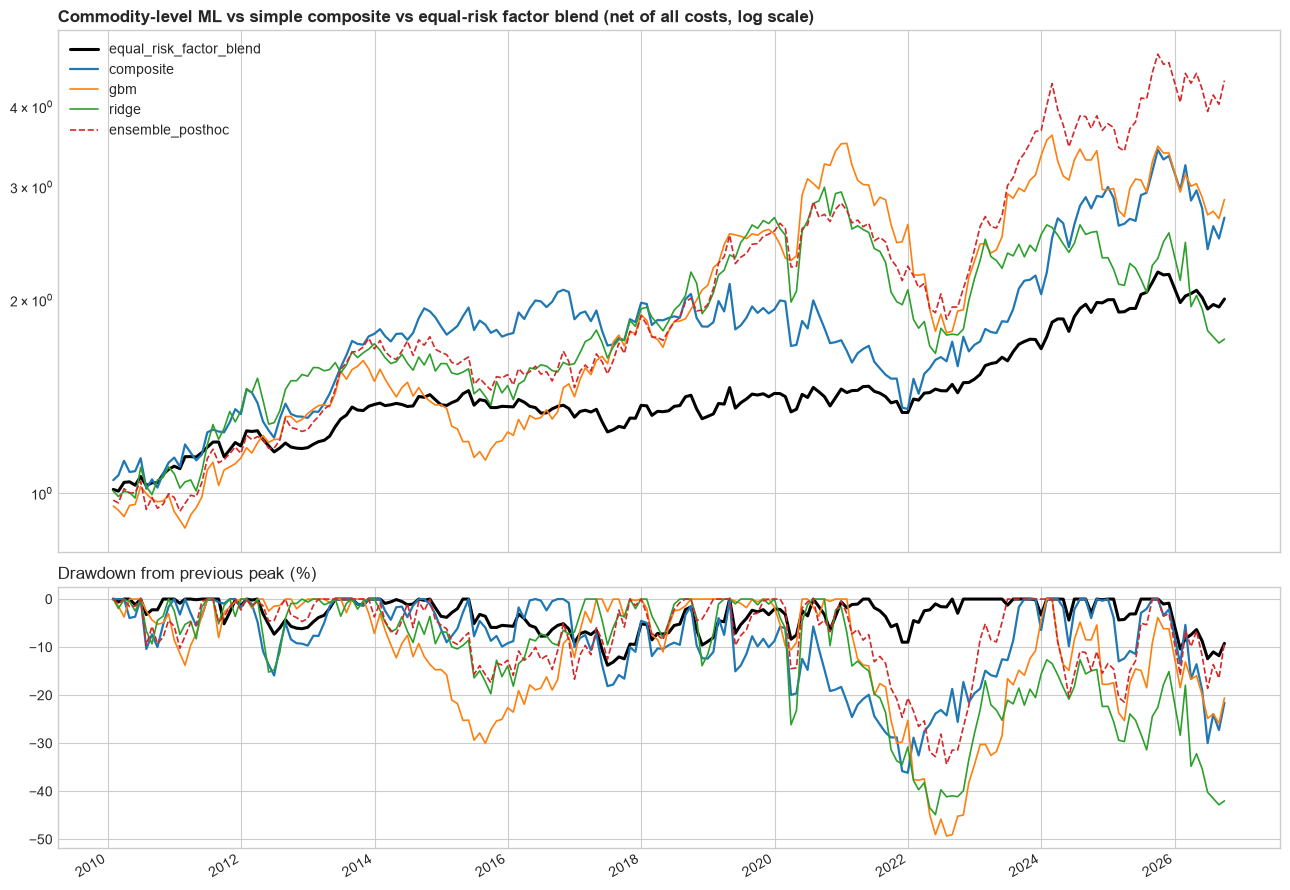

Notebook 08 conclusions
  Composite (no ML)        : Sharpe 0.43, max DD -36%
  Gradient boosting        : Sharpe 0.45 (vs composite t = 0.07)
  Ridge                    : Sharpe 0.27 (vs composite t = -0.56)
  Ensemble (post-hoc)      : Sharpe 0.62 (vs composite t = 0.82)
  Equal-risk factor blend  : Sharpe 0.55, max DD -14%

Saved 5 tables (reports/tables), predictions and portfolio returns (data/processed), chart (reports/figures)


In [10]:
# ============================================================
# 08 · Cell 8 — Charts, conclusions and save
# ============================================================
TABLES_DIR = PATHS.root / "reports" / "tables"

fig, (ax_cum, ax_dd) = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                                    gridspec_kw={"height_ratios": [2, 1]})
styles = {"equal_risk_factor_blend": {"color": "black", "lw": 2.2},
          "composite": {"lw": 1.6}, "gbm": {"lw": 1.2}, "ridge": {"lw": 1.2},
          "ensemble_posthoc": {"lw": 1.2, "ls": "--"}}
for name, style in styles.items():
    wealth = (1 + ls_net[name]).cumprod()
    wealth.plot(ax=ax_cum, label=name, **style)
    ((wealth / wealth.cummax() - 1) * 100).plot(ax=ax_dd, legend=False, **style)
ax_cum.set_yscale("log")
ax_cum.set_title("Commodity-level ML vs simple composite vs equal-risk factor blend "
                 "(net of all costs, log scale)", loc="left", fontweight="bold")
ax_cum.legend(loc="upper left")
ax_dd.set_title("Drawdown from previous peak (%)", loc="left")
ax_dd.set_xlabel("")
fig.tight_layout()
fig.savefig(PATHS.figures / "08_commodity_ml_oos.png", dpi=150)
plt.show()

# Save results
ls_table.to_csv(TABLES_DIR / "08_portfolio_performance.csv")
pd.DataFrame(head_to_head).T.to_csv(TABLES_DIR / "08_head_to_head.csv")
commodity_results.to_csv(TABLES_DIR / "08_prediction_quality.csv")
effects.to_csv(TABLES_DIR / "08_gbm_conditional_effects.csv")
pd.DataFrame(conditional_ic).to_csv(TABLES_DIR / "08_conditional_ic.csv")
commodity_predictions.to_parquet(PATHS.processed / "commodity_ml_predictions.parquet")
ls_net.to_parquet(PATHS.processed / "commodity_ml_portfolio_returns.parquet")

print("Notebook 08 conclusions")
print(f"  Composite (no ML)        : Sharpe {ls_table.at['composite', 'sharpe']:.2f}, "
      f"max DD {ls_table.at['composite', 'max_dd_%']:.0f}%")
print(f"  Gradient boosting        : Sharpe {ls_table.at['gbm', 'sharpe']:.2f} "
      f"(vs composite t = {head_to_head['gbm - composite']['t_stat_nw']:.2f})")
print(f"  Ridge                    : Sharpe {ls_table.at['ridge', 'sharpe']:.2f} "
      f"(vs composite t = {head_to_head['ridge - composite']['t_stat_nw']:.2f})")
print(f"  Ensemble (post-hoc)      : Sharpe {ls_table.at['ensemble_posthoc', 'sharpe']:.2f} "
      f"(vs composite t = {head_to_head['ensemble_posthoc - composite']['t_stat_nw']:.2f})")
print(f"  Equal-risk factor blend  : Sharpe {ls_table.at['equal_risk_factor_blend', 'sharpe']:.2f}, "
      f"max DD {ls_table.at['equal_risk_factor_blend', 'max_dd_%']:.0f}%")
print("\nSaved 5 tables (reports/tables), predictions and portfolio returns (data/processed), chart (reports/figures)")